In [1]:
import importlib

import numpy.random

import velogp
import torch
from matplotlib import pyplot

L = 5e6
v0 = 1e3
Tr = L/(2*v0)
origins = torch.tensor([2e6, 4e6], dtype=torch.int32)
h_tgrid = torch.linspace(0, 3600, steps=11, dtype=torch.double)
g_xranges_l = torch.tensor([1e6, 4.5e6], dtype=torch.int32)
g_xranges_u = torch.tensor([1.1e6, 4.6e6], dtype=torch.int32)

In [2]:
importlib.reload(velogp)
m = velogp.VelocityModel(L, True, origins, h_tgrid, g_xranges_l, g_xranges_u)

m.h_log_raw[:] = torch.log(torch.tensor([1, 2, 4, 4, 2, 1, 0.25, 0.1, 0.1, 0.25, 1], dtype=torch.double))
m.g_delta = torch.tensor([10,2], dtype=torch.double)

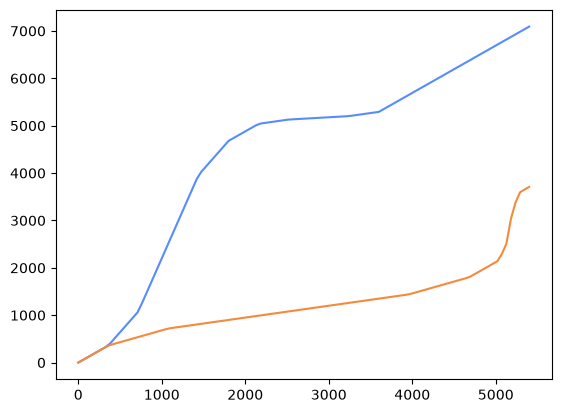

In [3]:
t = torch.linspace(0, 3600*1.5, steps=100)
pyplot.plot(t, m.H(t).detach().numpy(), label="H")
pyplot.plot(t, m.Hinv(t).detach().numpy(), label="Hinv")

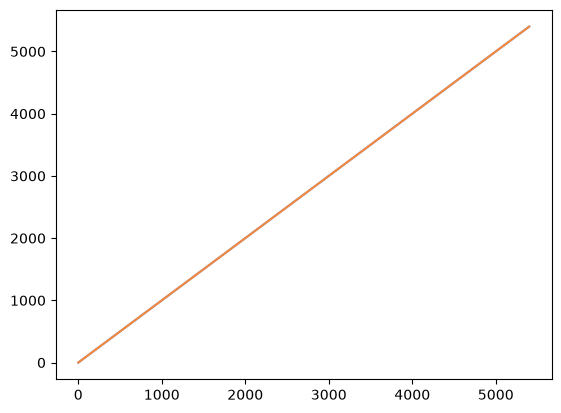

In [4]:
t = torch.linspace(0, 3600*1.5, steps=100)
pyplot.plot(t, m.Hinv(m.H(t)).detach().numpy(), label="H(Hinv)")
pyplot.plot(t, m.H(m.Hinv(t)).detach().numpy(), label="Hinv(H)")

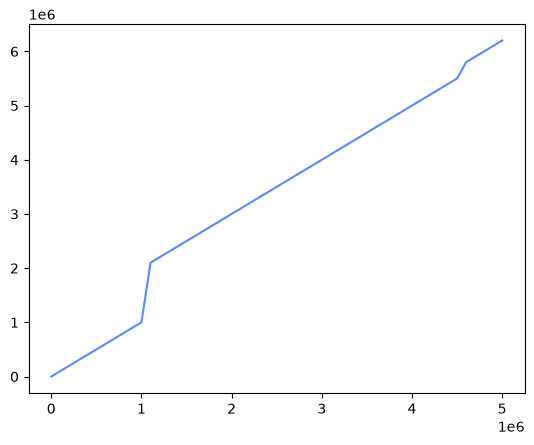

In [5]:
x = torch.linspace(0, L, steps=1000)
pyplot.plot(x, m.G_0(x).detach().numpy())

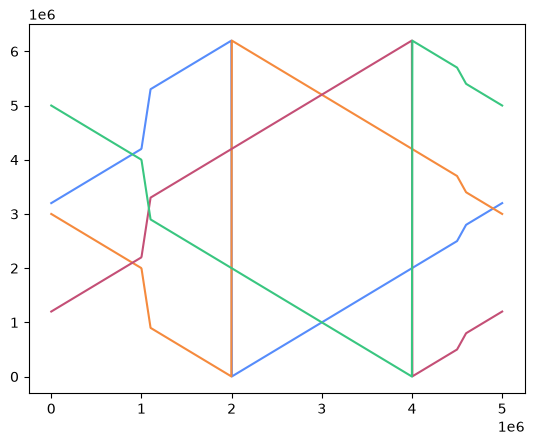

In [6]:
g1f = m.G(x, m.origins[0], torch.tensor([+1.0])).detach().numpy()
g1r = m.G(x, m.origins[0], torch.tensor([-1.0])).detach().numpy()
g2f = m.G(x, m.origins[1], torch.tensor([+1.0])).detach().numpy()
g2r = m.G(x, m.origins[1], torch.tensor([-1.0])).detach().numpy()
pyplot.plot(x, g1f, label="origin 1 fwd")
pyplot.plot(x, g1r, label="origin 1 rev")
pyplot.plot(x, g2f, label="origin 2 fwd")
pyplot.plot(x, g2r, label="origin 2 rev")

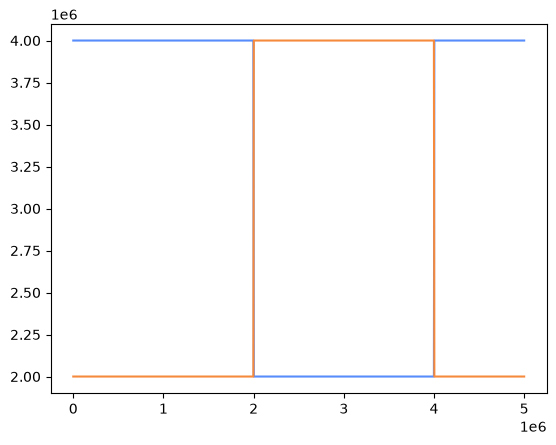

In [7]:
(i_l, i_r) = m.surrounding_origins(x)
pyplot.plot(x, m.origins[i_l], label="left")
pyplot.plot(x, m.origins[i_r], label="right")

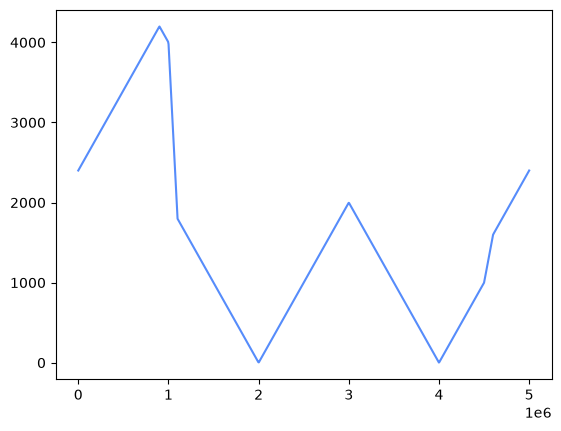

In [8]:
pyplot.plot(x, m.T(x).detach().numpy())

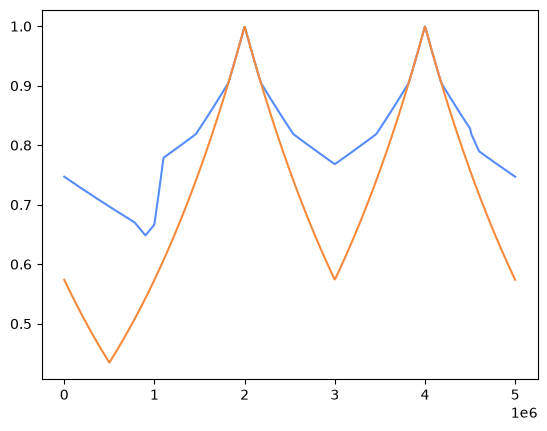

In [9]:
p = m.P(x).detach().numpy()
m0 = velogp.VelocityModel(L, True, origins, h_tgrid, g_xranges_l, g_xranges_u)
m0.g_log = torch.nn.Parameter(torch.log(torch.tensor([10,0.1], dtype=torch.double)))
p0 = m0.P(x).detach().numpy()
pyplot.plot(x, p, label="v=v(t)")
pyplot.plot(x, p0, label="v=v0")

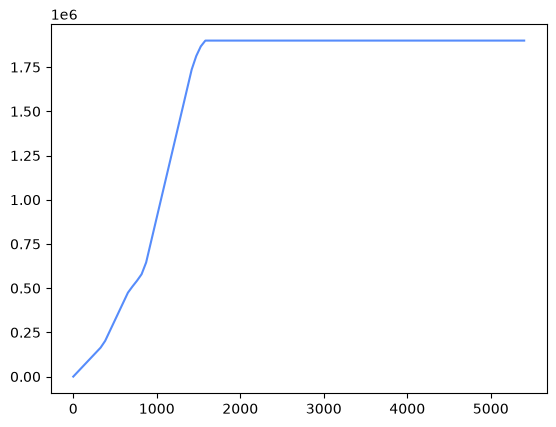

In [10]:
tab_state, tab_x, tab_dx, tab_v = m.trajectories(t)
pyplot.plot(t, tab_dx[:, 3])
